In [25]:
import sys
sys.path.append("..")
import numpy as np
from src.hedging import compute_pnl

In [26]:
S_test = np.array([[100, 102, 105]])
deltas_test = np.array([[0.51, 0.70]])

print(compute_pnl(S_test, deltas_test, p0=2.29, K=100, c=0.001))

[0.33962]


In [27]:
from src.simulation import simulate_gbm
from src.black_scholes import bs_price, bs_delta

In [28]:
S0,K,sigma,T,n_steps = 100,100,0.2,30/365,30
dt = T/n_steps
S =simulate_gbm(S0 = S0,  mu = 0, sigma = sigma, T = T, n_steps = n_steps, seed = 42, n_paths=100000)
tau = T - np.arange(n_steps)*dt


deltas = bs_delta(S[:, : -1], K, tau, sigma)
deltas.shape



(100000, 30)

In [29]:
#bs_price(S,K,tau,sigma)
p0 = bs_price(S0,K,T,sigma)
print(p0)

pnl_bs = compute_pnl(S, deltas, p0, K, c=0.0)
pnl_none = compute_pnl(S, np.zeros_like(deltas), p0, K, c=0.0)

print("no hedge:", pnl_none.mean(), pnl_none.std())
print("BS delta:", pnl_bs.mean(), pnl_bs.std())

2.2871506280449694
no hedge: -0.002481621370722777 3.459615709107045
BS delta: 0.0003667340558500123 0.35805697812331266


In [30]:
x = 67

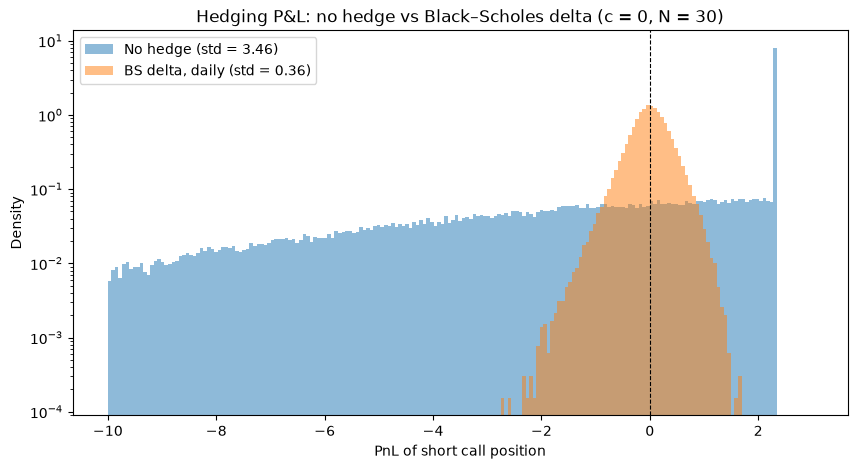

In [32]:
#proceeding with ploting both pnl
import matplotlib.pyplot as plt


bins = np.linspace(-10, 3, 200)   # the whole bucket of 2 distributions

plt.figure(figsize=(10, 5))
plt.hist(pnl_none, bins=bins, alpha=0.5, density=True, label=f"No hedge (std = {pnl_none.std():.2f})")
plt.hist(pnl_bs,   bins=bins, alpha=0.5, density=True, label=f"BS delta, daily (std = {pnl_bs.std():.2f})")
plt.axvline(0, color="black", ls="--", lw=0.8)
plt.xlabel("PnL of short call position")
plt.ylabel("Density")
plt.title("Hedging P&L: no hedge vs Black–Scholes delta (c = 0, N = 30)")
plt.legend()
plt.yscale("log")
plt.savefig("../figures/pnl_hist_bs_vs_none.png", dpi=150, bbox_inches="tight")
plt.show()